# 06 Alpha diversity

Input: taxonomy-filtered ASV table and sequences from `03_taxonomy.ipynb` (`table_fungi_filtered.qza`, `rep_set_fungi_filtered.qza`), metadata`Final_metadata_with_GHSL`)

Output (`processed_ignored/06_diversity/`): rarefaction curves, core diversity metrics (also used for beta diversity), alpha diversity group comparisons

No phylogenetic tree is built (ITS sequences cannot be reliably aligned), so Faith PD and UniFrac are replaced by k-mer based metrics (q2-kmerizer).

---
extended version

# 06 Alpha Diversity

**Input:**<br>

`processed_ignored/03_taxonomy/`
- taxonomy-filtered fungal ASV feature table (`table_fungi_filtered.qza`)
- taxonomy-filtered fungal representative ASV sequences (`rep_set_fungi_filtered.qza`)
<br>

`raw/`
- sample metadata with GHSL settlement classifications (`Final_metadata_with_GHSL.csv`)

**Steps:**<br>

<table>
  <tr>
    <td>Prepare sample metadata →</td>
    <td>Inspect rarefaction curves and select 16,000 reads per sample →</td>
    <td>Compute ASV diversity metrics →</td>
    <td>Compare k-mer sizes and compute final metrics at k = 8 →</td>
    <td>Test ASV alpha diversity for group differences and correlations with metadata</td>
  </tr>
</table>


**Output:**<br>

`processed_ignored/06_diversity/`
- ASV-based core diversity results for alpha and beta diversity (`core_metrics/`)
- k-mer-based core diversity results at k = 8 for alpha and beta diversity (`kmerizer/`)
<br>

`processed/06_diversity/`
- alpha rarefaction curves (`alpha_rarefaction.qzv`)
- Shannon diversity comparison across ASVs and k-mer sizes (`shannon_by_kmer_size.png`)

## 0 setup

In [1]:
import os
import pandas as pd
import qiime2 as q2
from qiime2 import Visualization,  Artifact

%matplotlib inline

In [2]:
raw_dir = '../data/raw'
in_dir  = '../data/processed_ignored/03_taxonomy'
out_dir = '../data/processed_ignored/06_diversity'
vis_dir = '../data/processed/06_diversity'

table    = f'{in_dir}/table_fungi_filtered.qza'
rep_seqs = f'{in_dir}/rep_set_fungi_filtered.qza'
metadata = f'{out_dir}/Final_metadata_with_GHSL.tsv'

In [3]:
!mkdir -p $out_dir $vis_dir

## 01 Metadata with numeric columns

In [4]:
import numpy as np

meta_file = f'{raw_dir}/Final_metadata_with_GHSL.csv'   # <-- 改成实际路径

md = pd.read_csv(meta_file)                              
md = md.set_index('ID')
md.index.name = 'sample-id'

# "Not provided" to empty not another catogory
md = md.replace('Not provided', np.nan)

numeric_cols = ['latitude_sample', 'longitude_sample', 'age_years_sample',
                'height_cm_sample', 'weight_kg_sample', 'bmi_sample']
for col in numeric_cols:
    md[col] = pd.to_numeric(md[col], errors='coerce')

md.to_csv(metadata, sep='\t')                       

print(md['Settlement_Type'].value_counts(dropna=False))

Settlement_Type
Rural       65
Urban       56
Suburban    24
NaN          5
Name: count, dtype: int64


## 02 choosing the sampling depth
if we look the ovserved feature， I would say 16000 is good

In [5]:
reads_per_sample = Artifact.load(table).view(pd.DataFrame).sum(axis=1).sort_values()
print(reads_per_sample.describe().round(0))
reads_per_sample.head(5)   # the 5 samples with the fewest reads

count       150.0
mean      60226.0
std       20230.0
min       16402.0
25%       46009.0
50%       62302.0
75%       74904.0
max      108777.0
dtype: float64


ERR5327557    16402.0
ERR5327284    17556.0
ERR5327566    20152.0
ERR5327596    20968.0
ERR5327433    24097.0
dtype: float64

In [6]:
!qiime diversity alpha-rarefaction \
    --i-table $table \
    --p-max-depth 60000 \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/alpha_rarefaction.qzv

Saved Visualization to: ../data/processed/06_diversity/alpha_rarefaction.qzv


In [ ]:
Visualization.load(f'{vis_dir}/alpha_rarefaction.qzv')

In [8]:
# Fixed rarefaction depth: keeps all samples; Shannon is flat and observed features is close to its plateau at this depth (see alpha rarefaction curves above)
sampling_depth = 16000
n_kept = (reads_per_sample >= sampling_depth).sum()
print(f'sampling depth: {sampling_depth}')
print(f'samples kept: {n_kept} of {len(reads_per_sample)}')

sampling depth: 16000
samples kept: 150 of 150


## 03 Core diversity metrics

In [9]:
!qiime diversity core-metrics \
  --i-table $table \
  --m-metadata-file $metadata \
  --p-sampling-depth $sampling_depth \
  --output-dir $out_dir/core_metrics

Saved FeatureTable[Frequency] to: ../data/processed_ignored/06_diversity/core_metrics/rarefied_table.qza
Saved SampleData[AlphaDiversity] to: ../data/processed_ignored/06_diversity/core_metrics/observed_features_vector.qza
Saved SampleData[AlphaDiversity] to: ../data/processed_ignored/06_diversity/core_metrics/shannon_vector.qza
Saved SampleData[AlphaDiversity] to: ../data/processed_ignored/06_diversity/core_metrics/evenness_vector.qza
Saved DistanceMatrix to: ../data/processed_ignored/06_diversity/core_metrics/jaccard_distance_matrix.qza
Saved DistanceMatrix to: ../data/processed_ignored/06_diversity/core_metrics/bray_curtis_distance_matrix.qza
Saved PCoAResults to: ../data/processed_ignored/06_diversity/core_metrics/jaccard_pcoa_results.qza
Saved PCoAResults to: ../data/processed_ignored/06_diversity/core_metrics/bray_curtis_pcoa_results.qza
Saved Visualization to: ../data/processed_ignored/06_diversity/core_metrics/jaccard_emperor.qzv
Saved Visualization to: ../data/processed_ignore

## 04 try different k-mer size
ITS sequences cannot be reliably aligned, so no phylogenetic tree is built. Instead, sequences are split into k-mers (short subsequences of length k) with q2-kmerizer, and diversity is computed on the k-mer counts.

The k-mer size affects the results. We therefore compare several k-mer sizes (4, 6, 8, 12, 16).

In [10]:
import os

kmer_sizes = [4, 6, 8, 12, 16]

for k in kmer_sizes:
    outdir = f'{out_dir}/kmerizer_k{k}'

    # skip k values that are already finished
    if os.path.exists(f'{outdir}/shannon_vector.qza'):
        print(f'k={k}: already done, skipping')
        continue
    # remove incomplete output from an interrupted run
    if os.path.exists(outdir):
        !rm -rf {outdir}

    cmd = (f"qiime kmerizer core-metrics "
           f"--i-table {table} "
           f"--i-sequences {rep_seqs} "
           f"--m-metadata-file {metadata} "
           f"--p-sampling-depth {sampling_depth} "
           f"--p-kmer-size {k} "
           f"--output-dir {outdir}")
    print(cmd)
    !{cmd}

qiime kmerizer core-metrics --i-table ../data/processed_ignored/03_taxonomy/table_fungi_filtered.qza --i-sequences ../data/processed_ignored/03_taxonomy/rep_set_fungi_filtered.qza --m-metadata-file ../data/processed_ignored/06_diversity/Final_metadata_with_GHSL.tsv --p-sampling-depth 16000 --p-kmer-size 4 --output-dir ../data/processed_ignored/06_diversity/kmerizer_k4
Saved FeatureTable[Frequency] to: ../data/processed_ignored/06_diversity/kmerizer_k4/rarefied_table.qza
Saved FeatureTable[Frequency] to: ../data/processed_ignored/06_diversity/kmerizer_k4/kmer_table.qza
Saved SampleData[AlphaDiversity] to: ../data/processed_ignored/06_diversity/kmerizer_k4/observed_features_vector.qza
Saved SampleData[AlphaDiversity] to: ../data/processed_ignored/06_diversity/kmerizer_k4/shannon_vector.qza
Saved DistanceMatrix to: ../data/processed_ignored/06_diversity/kmerizer_k4/jaccard_distance_matrix.qza
Saved DistanceMatrix to: ../data/processed_ignored/06_diversity/kmerizer_k4/bray_curtis_distance_

### 4.1 Comparison of k-mer sizes

Spearman correlation of Shannon diversity between k-mer sizes and the ASV-based Shannon diversity. High correlations mean that the ranking of samples does not depend much on the chosen k.

In [11]:
shannon = {'ASV': Artifact.load(f'{out_dir}/core_metrics/shannon_vector.qza').view(pd.Series)}
for k in kmer_sizes:
    shannon[f'k={k}'] = Artifact.load(f'{out_dir}/kmerizer_k{k}/shannon_vector.qza').view(pd.Series)

shannon = pd.DataFrame(shannon)
shannon.corr(method='spearman').round(2)

,ASV,k=4,k=6,k=8,k=12,k=16
ASV,1.00,0.11,0.41,0.59,0.73,0.78
k=4,0.11,1.00,0.88,0.77,0.65,0.61
k=6,0.41,0.88,1.00,0.94,0.87,0.84
k=8,0.59,0.77,0.94,1.00,0.97,0.95
k=12,0.73,0.65,0.87,0.97,1.00,0.99
k=16,0.78,0.61,0.84,0.95,0.99,1.00


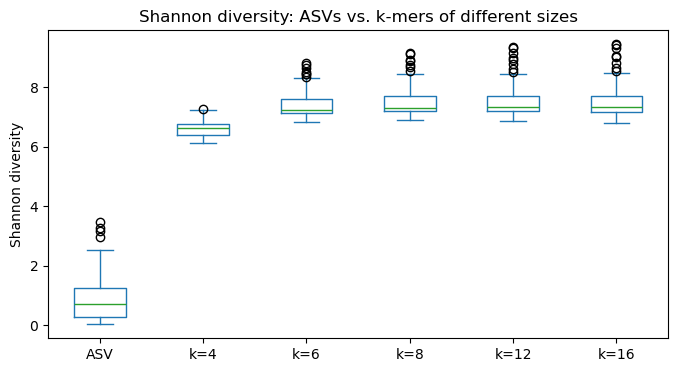

In [12]:
import matplotlib.pyplot as plt

shannon.plot(kind='box', figsize=(8, 4))
plt.ylabel('Shannon diversity')
plt.title('Shannon diversity: ASVs vs. k-mers of different sizes')
plt.savefig(f'{vis_dir}/shannon_by_kmer_size.png', dpi=200, bbox_inches='tight')
plt.show()

We chose k = 8 because the results were stable from this size onwards (ρ ≥ 0.94 with neighbouring k values), while k = 4 could hardly distinguish samples. 
Larger k values became increasingly similar to the ASV-based results (ρ = 0.78 at k = 16) and therefore added little information about sequence similarity.

## 04 k-mer based diversity (replaces phylogenetic metrics)

In [14]:
!qiime kmerizer core-metrics \
  --i-table $table \
  --i-sequences $rep_seqs \
  --m-metadata-file $metadata \
  --p-sampling-depth $sampling_depth \
  --p-kmer-size 8 \
  --output-dir $out_dir/kmerizer

Saved FeatureTable[Frequency] to: ../data/processed_ignored/06_diversity/kmerizer/rarefied_table.qza
Saved FeatureTable[Frequency] to: ../data/processed_ignored/06_diversity/kmerizer/kmer_table.qza
Saved SampleData[AlphaDiversity] to: ../data/processed_ignored/06_diversity/kmerizer/observed_features_vector.qza
Saved SampleData[AlphaDiversity] to: ../data/processed_ignored/06_diversity/kmerizer/shannon_vector.qza
Saved DistanceMatrix to: ../data/processed_ignored/06_diversity/kmerizer/jaccard_distance_matrix.qza
Saved DistanceMatrix to: ../data/processed_ignored/06_diversity/kmerizer/bray_curtis_distance_matrix.qza
Saved PCoAResults to: ../data/processed_ignored/06_diversity/kmerizer/jaccard_pcoa_results.qza
Saved PCoAResults to: ../data/processed_ignored/06_diversity/kmerizer/bray_curtis_pcoa_results.qza
Saved Visualization to: ../data/processed_ignored/06_diversity/kmerizer/scatterplot.qzv


## 05 Alpha diversity: group comparisons
alpha-group-significance tests categorical columns (Kruskal-Wallis, with pairwise tests), alpha-correlation tests numeric columns (Spearman). Look at the q-values (FDR-corrected), not only the p-values, and at the group sizes.

In [15]:
%%bash -s "$out_dir" "$vis_dir" "$metadata"
out_dir=$1; vis_dir=$2; metadata=$3

for metric in shannon observed_features evenness; do
  qiime diversity alpha-group-significance \
    --i-alpha-diversity $out_dir/core_metrics/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/${metric}_group_significance.qzv

  qiime diversity alpha-correlation \
    --i-alpha-diversity $out_dir/core_metrics/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/${metric}_correlation.qzv
done

Saved Visualization to: ../data/processed/06_diversity/shannon_group_significance.qzv
Saved Visualization to: ../data/processed/06_diversity/shannon_correlation.qzv
Saved Visualization to: ../data/processed/06_diversity/observed_features_group_significance.qzv
Saved Visualization to: ../data/processed/06_diversity/observed_features_correlation.qzv
Saved Visualization to: ../data/processed/06_diversity/evenness_group_significance.qzv
Saved Visualization to: ../data/processed/06_diversity/evenness_correlation.qzv


In [ ]:
Visualization.load(f'{vis_dir}/shannon_group_significance.qzv')